# 03 — Anomaly Detection & Cleaning Decision

**SolarVision operational layer**

### What this notebook does
1. Loads the held-out forecast predictions from training
2. Flags **sustained under-production** vs forecast (daytime only)
3. Builds a **transparent cleaning cost–benefit** decision from the same CSV fields
4. States limits clearly (no claim that dust is proven as the cause)

### Inputs required
- `forecast_test_predictions_24h.csv` (from `02_training.ipynb`)
- Optionally full `processed_data/forecast_ready.parquet` for dust / P_clean context

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PRED_PATH = Path("forecast_test_predictions_24h.csv")
FULL_PATH = Path("processed_data/forecast_ready.parquet")
OUT_DIR = Path(".")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

assert PRED_PATH.exists(), "Run 02_training.ipynb first"

## 1. Load predictions

In [2]:
res = pd.read_csv(PRED_PATH, parse_dates=True, index_col=0)
res.index = pd.to_datetime(res.index)
res = res.sort_index()

# Enrich with dust / clean power if processed table available
if FULL_PATH.exists():
    full = pd.read_parquet(FULL_PATH)
    cols = [c for c in [
        "dust_density_reconstructed_PCHIP_gm2", "P_clean_W", "G_POA_Wm2", "precipitation_mm"
    ] if c in full.columns]
    res = res.join(full[cols], how="left", rsuffix="_full")

print(res.shape)
print(res.index.min(), "→", res.index.max())
res.head(3)

(642, 11)
2022-07-21 06:00:00 → 2022-08-16 23:00:00


,actual_power_W,predicted_power_W,predicted_blend_W,residual_W,residual_pct,is_daytime,P_clean_W,dust_density_reconstructed_PCHIP_gm2,P_clean_W_full,G_POA_Wm2,precipitation_mm
datetime,,,,,,,,,,,
2022-07-21 06:00:00,0.39,0.985391,0.917078,-0.595391,-60.421796,1,0.86,19.2894,0.86,9.97,0.0
2022-07-21 07:00:00,2.04,2.306287,2.005257,-0.266287,-11.546142,1,2.29,19.2769,2.29,26.19,0.0
2022-07-21 08:00:00,4.56,5.215234,4.747047,-0.655234,-12.563839,1,5.38,19.2638,5.38,64.72,0.0


## 2. Anomaly rules (daytime only)

Design choices aligned with operational caution:

| Parameter | Default | Meaning |
|-----------|---------|--------|
| `DROP_PCT` | 20% | actual ≤ forecast × (1 − 0.20) |
| `MIN_PRED_W` | 5 W | ignore tiny forecast hours |
| `WINDOW` | 6 h | lookback |
| `MIN_HITS` | 3 | hits inside window to raise alert |

**Interpretation:** alert = *production below model expectation*, not a medical diagnosis of dust.

In [3]:
DROP_PCT = 0.20
MIN_PRED_W = 5.0
WINDOW = 6
MIN_HITS = 3

day = res["is_daytime"].astype(bool) if "is_daytime" in res.columns else (res["actual_power_W"] > 0.5)

under = (
    day
    & (res["predicted_power_W"] >= MIN_PRED_W)
    & (res["actual_power_W"] <= res["predicted_power_W"] * (1 - DROP_PCT))
)
res["is_anomaly_hour"] = under.astype(int)

res["anomaly_count_6h"] = (
    res["is_anomaly_hour"].rolling(WINDOW, min_periods=1).sum()
)
res["anomaly_alert"] = (res["anomaly_count_6h"] >= MIN_HITS).astype(int)

res["alert_reason"] = np.where(
    res["anomaly_alert"] == 1,
    f"Actual power ≥{int(DROP_PCT*100)}% below forecast for ≥{MIN_HITS} of last {WINDOW} hours (daytime).",
    "",
)

n_hours = int(res["is_anomaly_hour"].sum())
n_alerts = int(res["anomaly_alert"].sum())
print(f"Anomaly hours: {n_hours}")
print(f"Sustained alerts: {n_alerts}")

alerts = res[res["anomaly_alert"] == 1][[
    "actual_power_W", "predicted_power_W", "residual_W", "residual_pct",
    "anomaly_count_6h", "alert_reason"
]].copy()
alerts

Anomaly hours: 10
Sustained alerts: 0


,actual_power_W,predicted_power_W,residual_W,residual_pct,anomaly_count_6h,alert_reason
datetime,,,,,,


## 3. Simple quality view of alerts

If `P_clean_W` exists, compare soiling gap on alert vs non-alert daytime hours.
This is **descriptive only** — correlation ≠ proven cause.

In [4]:
if "P_clean_W" in res.columns:
    res["soiling_gap_W"] = (res["P_clean_W"] - res["actual_power_W"]).clip(lower=0)
    day_res = res[day]
    print("Mean soiling gap (W) — daytime:")
    print("  alert=1:", day_res.loc[day_res.anomaly_alert==1, "soiling_gap_W"].mean())
    print("  alert=0:", day_res.loc[day_res.anomaly_alert==0, "soiling_gap_W"].mean())
else:
    print("P_clean_W not available — skip soiling gap comparison (data limitation).")

if "dust_density_reconstructed_PCHIP_gm2" in res.columns:
    day_res = res[day]
    print("Mean dust density — daytime:")
    print("  alert=1:", day_res.loc[day_res.anomaly_alert==1, "dust_density_reconstructed_PCHIP_gm2"].mean())
    print("  alert=0:", day_res.loc[day_res.anomaly_alert==0, "dust_density_reconstructed_PCHIP_gm2"].mean())

Mean soiling gap (W) — daytime:
  alert=1: nan
  alert=0: 6.670764872521246
Mean dust density — daytime:
  alert=1: nan
  alert=0: 18.260743059490082


## 4. Plot forecast vs actual with alerts

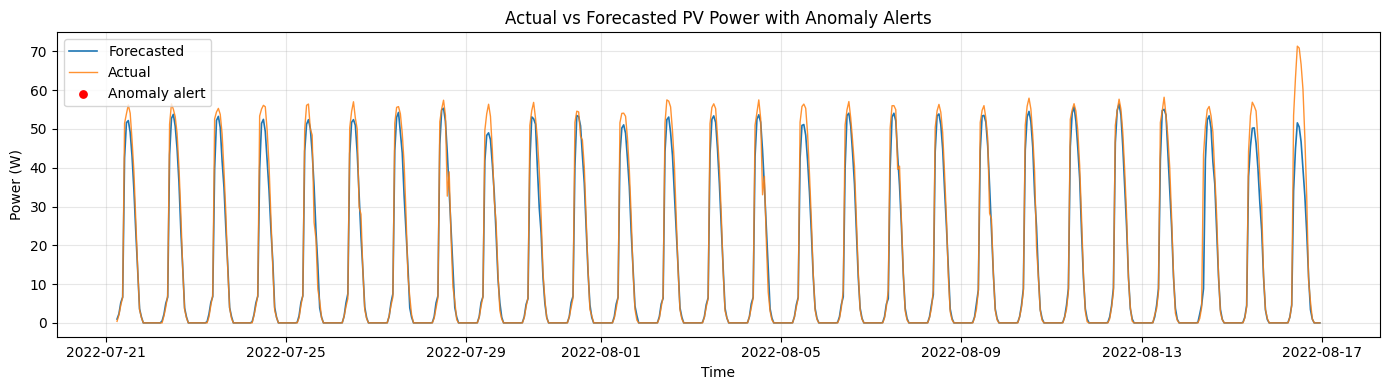

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(res.index, res["predicted_power_W"], label="Forecasted", lw=1.2)
ax.plot(res.index, res["actual_power_W"], label="Actual", lw=1.0, alpha=0.85)
al = res[res["anomaly_alert"] == 1]
ax.scatter(al.index, al["actual_power_W"], color="red", s=28, zorder=5, label="Anomaly alert")
ax.set_title("Actual vs Forecasted PV Power with Anomaly Alerts")
ax.set_ylabel("Power (W)")
ax.set_xlabel("Time")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "anomaly_detection_24h.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Cleaning decision (transparent economics)

Uses **only energy totals derived from this dataset window** plus **user-provided** price/cost assumptions.

$$\text{net benefit} = (\text{loss kWh} \times \text{recoverable fraction} \times \text{price}) - \text{cleaning cost}$$

No guaranteed savings claim.

In [6]:
def cleaning_decision(
    expected_energy_kwh: float,
    actual_energy_kwh: float,
    cleaning_cost: float,
    electricity_price: float,
    recoverable_fraction: float = 0.8,
    horizon_days: int = 7,
):
    loss = max(expected_energy_kwh - actual_energy_kwh, 0.0)
    recovered = loss * recoverable_fraction
    revenue = recovered * electricity_price
    net = revenue - cleaning_cost
    return {
        "horizon_days": horizon_days,
        "expected_energy_kwh": expected_energy_kwh,
        "actual_energy_kwh": actual_energy_kwh,
        "estimated_loss_kwh": loss,
        "recoverable_energy_kwh": recovered,
        "electricity_price": electricity_price,
        "revenue_gain": revenue,
        "cleaning_cost": cleaning_cost,
        "net_benefit": net,
        "decision": "Clean" if net > 0 else "Wait",
    }

In [7]:
# --- Build energy totals from the test window (module-scale Watts → kWh) ---
# Hourly power in W ≈ Wh for that hour; /1000 → kWh for THIS module only.

daytime = res[day].copy()
expected_kwh = daytime["predicted_power_W"].clip(lower=0).sum() / 1000.0
actual_kwh   = daytime["actual_power_W"].clip(lower=0).sum() / 1000.0

print(f"Daytime expected energy (module, test window): {expected_kwh:.3f} kWh")
print(f"Daytime actual energy   (module, test window): {actual_kwh:.3f} kWh")
print("Note: single 85W-class module → absolute kWh are small; scale with plant_scale for scenarios.")

Daytime expected energy (module, test window): 9.041 kWh
Daytime actual energy   (module, test window): 9.854 kWh
Note: single 85W-class module → absolute kWh are small; scale with plant_scale for scenarios.


In [8]:
# User-editable assumptions (NOT from the CSV — economic scenario inputs)
ELECTRICITY_PRICE = 2.0     # currency / kWh (example)
CLEANING_COST = 50.0        # currency per cleaning event (example)
RECOVERABLE = 0.80
PLANT_SCALE = 1000.0        # scale module energy to a hypothetical plant size

decision = cleaning_decision(
    expected_energy_kwh=expected_kwh * PLANT_SCALE,
    actual_energy_kwh=actual_kwh * PLANT_SCALE,
    cleaning_cost=CLEANING_COST,
    electricity_price=ELECTRICITY_PRICE,
    recoverable_fraction=RECOVERABLE,
    horizon_days=max(1, int((res.index.max() - res.index.min()).days) or 7),
)
decision

{'horizon_days': 26,
 'expected_energy_kwh': np.float64(9041.137005467874),
 'actual_energy_kwh': np.float64(9854.4),
 'estimated_loss_kwh': 0.0,
 'recoverable_energy_kwh': 0.0,
 'electricity_price': 2.0,
 'revenue_gain': 0.0,
 'cleaning_cost': 50.0,
 'net_benefit': -50.0,
 'decision': 'Wait'}

In [9]:
# Two illustrative scenarios (same energy, different cost)
scenarios = [
    cleaning_decision(expected_kwh * PLANT_SCALE, actual_kwh * PLANT_SCALE, cleaning_cost=50, electricity_price=2.0),
    cleaning_decision(expected_kwh * PLANT_SCALE, actual_kwh * PLANT_SCALE, cleaning_cost=5000, electricity_price=2.0),
]
scen_df = pd.DataFrame(scenarios)
scen_df

,horizon_days,expected_energy_kwh,actual_energy_kwh,estimated_loss_kwh,recoverable_energy_kwh,electricity_price,revenue_gain,cleaning_cost,net_benefit,decision
0,7,9041.137005,9854.4,0.0,0.0,2.0,0.0,50,-50.0,Wait
1,7,9041.137005,9854.4,0.0,0.0,2.0,0.0,5000,-5000.0,Wait


## 6. Tie latest alert → decision message

In [10]:
if len(alerts) > 0:
    latest = alerts.index.max()
    print("Latest anomaly alert at:", latest)
    print("Operational suggestion based on current cost assumptions:", decision["decision"])
    print("Net benefit (scenario):", round(decision["net_benefit"], 2))
else:
    print("No sustained anomaly alert in this test window under current thresholds.")

No sustained anomaly alert in this test window under current thresholds.


## 7. Save outputs

In [11]:
res.to_csv("anomaly_results_24h.csv")
alerts.to_csv("anomaly_alerts_24h.csv")
scen_df.to_csv("cleaning_decision_examples.csv", index=False)

print("Saved:")
print(" - anomaly_results_24h.csv")
print(" - anomaly_alerts_24h.csv")
print(" - cleaning_decision_examples.csv")
print(" - figures/anomaly_detection_24h.png")

Saved:
 - anomaly_results_24h.csv
 - anomaly_alerts_24h.csv
 - cleaning_decision_examples.csv
 - figures/anomaly_detection_24h.png


## Limits (must appear in project documentation)

1. Dataset is one Algerian site, ~6 months — not an Egyptian plant.
2. Forecast residual ≠ proof of dust; shading, calibration, clouds also reduce power.
3. Dust density is partly **reconstructed**, not continuous lab measurement every hour.
4. Cleaning economics use **user price/cost inputs**; module kWh scaled by `PLANT_SCALE` is hypothetical.
5. Alerts depend on threshold choices (`DROP_PCT`, `MIN_HITS`); tune with operator feedback.
6. No thermal/IR link in this notebook (Feature 1 is separate data).